# Smart surveillance system for Real-Time Multi-Threat Detection (Fall, Fight, and Fire)
Executed demo of the three detection engines. Logic checks use **synthetic** skeletons/flames (no real-world accuracy is claimed here); the pose-model cell uses a real photo. Real accuracy must be measured with `tools/evaluate.py` on labelled clips.

In [2]:
import os, sys, yaml, cv2, numpy as np
sys.path.insert(0, os.getcwd())
from IPython.display import Image, display
cfg = yaml.safe_load(open('config.yaml'))
print({k: cfg[k]['enabled'] for k in ('fall','fight','fire')})

{'fall': True, 'fight': True, 'fire': True}


## 1. Fall detection scenarios (10 FPS synthetic skeleton)

In [3]:
from kavach.fall import FallDetector
from tests.synth import skeleton, person
from tests.test_fall import seq, stand, lie, sit, bend, tilt
scen = {
 'fast fall, stays down':      [(2,stand),(0.5,tilt),(3,lie)],
 'fall then gets up fast':     [(2,stand),(0.5,tilt),(0.8,lie),(2,stand)],
 'walking / standing':         [(8,stand)],
 'sitting down':               [(2,stand),(8,sit)],
 'bending over':               [(2,stand),(1,bend),(5,lambda f: bend(1.0))],
 'slow lie-down (4 s)':        [(2,stand),(4,tilt),(3,lie)],
 'found lying 12 s':           [(12,lie)],
}
print(f"{'scenario':28s} -> alerts")
for name, parts in scen.items():
    d, ev = FallDetector(cfg['fall']), []
    for t,k,c in seq(parts): ev += d.update([person(1,k,c)], t)
    print(f"{name:28s} -> {[e.kind for e in ev] or 'none'}")

scenario                     -> alerts
fast fall, stays down        -> ['fall']
fall then gets up fast       -> none
walking / standing           -> none
sitting down                 -> none
bending over                 -> none
slow lie-down (4 s)          -> none
found lying 12 s             -> ['person_down']


## 2. Fight scenarios

In [4]:
import math
from kavach.fight import FightDetector
from tests.test_fight import two, punch_arm, H
def run(gen, secs):
    d, ev = FightDetector(cfg['fight']), []
    for i in range(int(secs*10)): ev += d.update(gen(i/10), i/10)
    return [e.kind for e in ev] or 'none'
def punching(t):
    e = punch_arm(t, 0); return two(t,300,420,a_arm={10:(336+e*0.30*H,280),8:(360+e*0.2*H*0.3,270)})
def scuffle(t):
    s = math.sin(2*math.pi*2.2*t)
    return two(t,300,400,a_arm={10:(340+60*s,280+40*s),9:(260-40*s,300)},b_arm={9:(360-60*s,280-40*s),10:(440+40*s,300)})
def shake(t):
    o = 8*math.sin(2*math.pi*0.8*t); return two(t,300,400,a_arm={10:(350+o,300)},b_arm={9:(350-o,300)})
for n,g,s in [('sustained punching',punching,6),('mutual scuffle',scuffle,8),('walking together',lambda t:two(t,100+30*t,220+30*t),8),
              ('standing close',lambda t:two(t,300,400),8),('slow handshake',shake,8)]:
    print(f'{n:22s} -> {run(g,s)}')

sustained punching     -> ['fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight']
mutual scuffle         -> ['fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight', 'fight']
walking together       -> none
standing close         -> none
slow handshake         -> none


## 3. Fire: flickering flame vs static orange objects (heuristic mode)

In [5]:
from kavach.fire import FireDetector
from tests.test_fire import background, flame, W, H as FH
fc = dict(cfg['fire']); fc['mode']='heuristic'
def trial(make, secs=6):
    d, ev, rng = FireDetector(dict(fc)), [], np.random.default_rng(0)
    for i in range(int(secs*10)): ev += d.update(make(rng), i/10)
    return [e.kind for e in ev] or 'none'
def flame_f(rng): f=background(rng); flame(f,rng); return f
def curtain(rng): f=background(rng); cv2.rectangle(f,(100,60),(260,300),(20,120,255),-1); return f
def sunset(rng): return np.full((FH,W,3),(30,140,255),np.uint8)
for n,m in [('flickering flame',flame_f),('static orange curtain',curtain),('orange sunset frame',sunset),('plain scene',background)]:
    print(f'{n:24s} -> {trial(m)}')

flickering flame         -> ['fire', 'fire', 'fire', 'fire']
static orange curtain    -> none
orange sunset frame      -> none
plain scene              -> none


## 4. Real pose model on a real photo (people detection + skeleton)

people found: 3


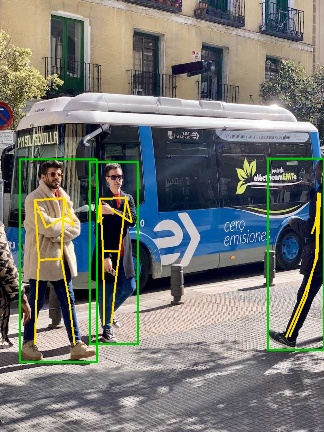

In [6]:
from kavach.pose import PoseEstimator
from kavach.tracker import Tracker
pe = PoseEstimator(cfg['pose']); img = cv2.imread('data/samples/street.jpg')
people = Tracker().update(pe.detect(img), 0.0)
vis = img.copy()
for p in people:
    x1,y1,x2,y2 = map(int,p.box); cv2.rectangle(vis,(x1,y1),(x2,y2),(0,200,0),3)
    for a,b in [(5,6),(5,7),(7,9),(6,8),(8,10),(5,11),(6,12),(11,12),(11,13),(13,15),(12,14),(14,16)]:
        if p.conf[a]>0.3 and p.conf[b]>0.3: cv2.line(vis,tuple(map(int,p.kpts[a])),tuple(map(int,p.kpts[b])),(0,220,255),3)
print('people found:', len(people))
display(Image(data=cv2.imencode('.jpg', cv2.resize(vis,None,fx=0.4,fy=0.4))[1].tobytes()))

## 5. Unit tests

In [ ]:
import subprocess
r = subprocess.run([sys.executable,'-m','pytest','-q','tests'],capture_output=True,text=True)
print(r.stdout[-400:])

31mE         Use -v to get more diff

tests\test_fight.py:67: AssertionError
=========================== short test summary info ===========================
FAILED tests/test_fight.py::test_single_high_five_burst_no_alert - AssertionError: assert [Event(kind='...9, 468, 466))] == []
1 failed, 20 passed in 6.32s



: 

## Limitations
See README: heuristic thresholds were validated only on synthetic data here; measure on real labelled clips with `tools/evaluate.py` before reporting any accuracy.